# AlphaRAD on RSNA dataset

In [1]:
# Install dependencies 
import subprocess
import sys
import time
from pathlib import Path

RUN_START = time.perf_counter()
REPO_URL = 'https://github.com/jz5426/ECCV-2026-AlphaRAD.git'
REPO_COMMIT = '59a28b0211081a99936da37902b3e5ee081056f5'
REPO = Path('/kaggle/working/alpharad_official')
INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
RESULTS = WORK / 'alpharad_rsna_results'
RESULTS.mkdir(parents=True, exist_ok=True)

packages = [
    'albumentations==1.3.1', 'transformers==4.57.1',
    'torchmetrics==1.8.2', 'jaxtyping==0.3.3',
    'huggingface_hub==0.36.0', 'hydra-core==1.3.2',
    'einops', 'nltk', 'timm==0.9.2', 'pydicom==3.0.1', 'SimpleITK',
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *packages], check=True)
if not (REPO / 'evaluate_zeroshot.py').is_file():
    subprocess.run(['git', 'clone', REPO_URL, str(REPO)], check=True)
subprocess.run(['git', '-C', str(REPO), 'checkout', '--detach', REPO_COMMIT], check=True)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print('AlphaRAD source:', REPO_COMMIT[:12])


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 904.5 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.9/55.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 40.2 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.0 which is incompatible.
Cloning into '/kaggle/working/alpharad_official'...


AlphaRAD source: 59a28b021108


HEAD is now at 59a28b0 .


In [2]:
# Set the fixed binary query and inference settings
import hashlib
import json
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
import torch
from huggingface_hub import HfApi, hf_hub_download, snapshot_download
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve,
)

SEED = 1234
TASK_EPOCHS = 0
INFERENCE_BATCH_SIZE = 2
NUM_WORKERS = 2
CONVERSION_WORKERS = 4
THRESHOLD = 0.5
QUERY_FINDING = 'Pneumonia'
DATASET_KEY = 'rsna_pneumonia'
SPLIT_REPO = 'Deepnoid/RadZero'
SPLIT_REVISION = '1e6e7d6295a13aa0a4a7e1c1e2bb36b9ef4e02e8'
SPLIT_FILENAME = 'data/RSNA/test.csv'

if not torch.cuda.is_available():
    raise RuntimeError('Select a GPU accelerator in Kaggle settings.')
cv2.setNumThreads(1)
print('GPU:', torch.cuda.get_device_name(0))
print('RSNA training epochs:', TASK_EPOCHS, '| fixed threshold:', THRESHOLD)


GPU: Tesla T4
RSNA training epochs: 0 | fixed threshold: 0.5


In [3]:
# Load the public RadZero test IDs cited by AlphaRAD
split_path = Path(hf_hub_download(
    repo_id=SPLIT_REPO, filename=SPLIT_FILENAME, revision=SPLIT_REVISION,
))
reference = pd.read_csv(split_path, dtype={'ID': str})
if len(reference) != 5337 or reference['ID'].nunique() != 5337:
    raise ValueError('The reference split must contain 5,337 unique image IDs.')
if not reference['ID'].str.fullmatch(r'[0-9a-fA-F-]{36}').all():
    raise ValueError('Unexpected RSNA image ID format.')
if not reference['classes'].isin([0, 1]).all() or reference['classes'].sum() != 1218:
    raise ValueError('The reference split must contain 1,218 positive images.')
(RESULTS / 'rsna_reference_split.csv').write_bytes(split_path.read_bytes())
print('Reference test split: 5,337 images | 1,218 positive | 4,119 negative')


data/RSNA/test.csv:   0%|          | 0.00/1.48M [00:00<?, ?B/s]

Reference test split: 5,337 images | 1,218 positive | 4,119 negative


In [4]:
# Match the benchmark IDs and labels to the attached RSNA DICOM files
data_roots = [
    path.parent for path in INPUT.rglob('stage_2_train_labels.csv')
    if (path.parent / 'stage_2_train_images').is_dir()
]
if len(data_roots) != 1:
    raise FileNotFoundError(
        'Attach one RSNA input containing stage_2_train_labels.csv '
        'and the extracted stage_2_train_images/ folder.'
    )
DATA_ROOT = data_roots[0]
IMAGE_ROOT = DATA_ROOT / 'stage_2_train_images'
raw_labels = pd.read_csv(DATA_ROOT / 'stage_2_train_labels.csv', usecols=['patientId', 'Target'])
image_labels = raw_labels.groupby('patientId')['Target'].max()
manifest = reference[['ID', 'classes']].rename(columns={'ID': 'patientId', 'classes': 'Target'}).copy()
manifest['Target'] = manifest['Target'].astype(int)
attached_labels = manifest['patientId'].map(image_labels)
if attached_labels.isna().any() or not np.array_equal(attached_labels.to_numpy(), manifest['Target'].to_numpy()):
    raise ValueError('The attached RSNA labels do not match the reference test IDs and targets.')
manifest['dicom_path'] = manifest['patientId'].map(lambda image_id: str(IMAGE_ROOT / f'{image_id}.dcm'))
missing = manifest.loc[~manifest['dicom_path'].map(lambda path: Path(path).is_file())]
if len(missing):
    raise FileNotFoundError(f'{len(missing)} reference DICOM images are missing.')
print('RSNA input:', DATA_ROOT)
print(f'Test set: {len(manifest):,} images | {manifest.Target.sum():,} positive')


RSNA input: /kaggle/input/competitions/rsna-pneumonia-detection-challenge
Test set: 5,337 images | 1,218 positive


In [5]:
# Convert the selected DICOM images
from cxrclip.data.dataformat_converter import resize_dicom_and_save

PNG_ROOT = WORK / f'alpharad_rsna_png_{REPO_COMMIT[:7]}'
PNG_ROOT.mkdir(parents=True, exist_ok=True)
conversion_start = time.perf_counter()

def convert_image(row):
    output = PNG_ROOT / f'{row.patientId}.png'
    if not output.is_file():
        resize_dicom_and_save(row.dicom_path, str(output), do_resize=True)
    with Image.open(output) as image:
        image.verify()
    return str(output)

image_paths = []
with ThreadPoolExecutor(max_workers=CONVERSION_WORKERS) as pool:
    converted = pool.map(convert_image, manifest.itertuples(index=False))
    for count, path in enumerate(converted, start=1):
        image_paths.append(path)
        if count % 500 == 0 or count == len(manifest):
            print(f'Prepared {count:,}/{len(manifest):,} images')
manifest['image'] = image_paths
conversion_seconds = time.perf_counter() - conversion_start
print(f'DICOM preparation: {conversion_seconds / 60:.1f} minutes')


Prepared 500/5,337 images
Prepared 1,000/5,337 images
Prepared 1,500/5,337 images
Prepared 2,000/5,337 images
Prepared 2,500/5,337 images
Prepared 3,000/5,337 images
Prepared 3,500/5,337 images
Prepared 4,000/5,337 images
Prepared 4,500/5,337 images
Prepared 5,000/5,337 images
Prepared 5,337/5,337 images
DICOM preparation: 0.6 minutes


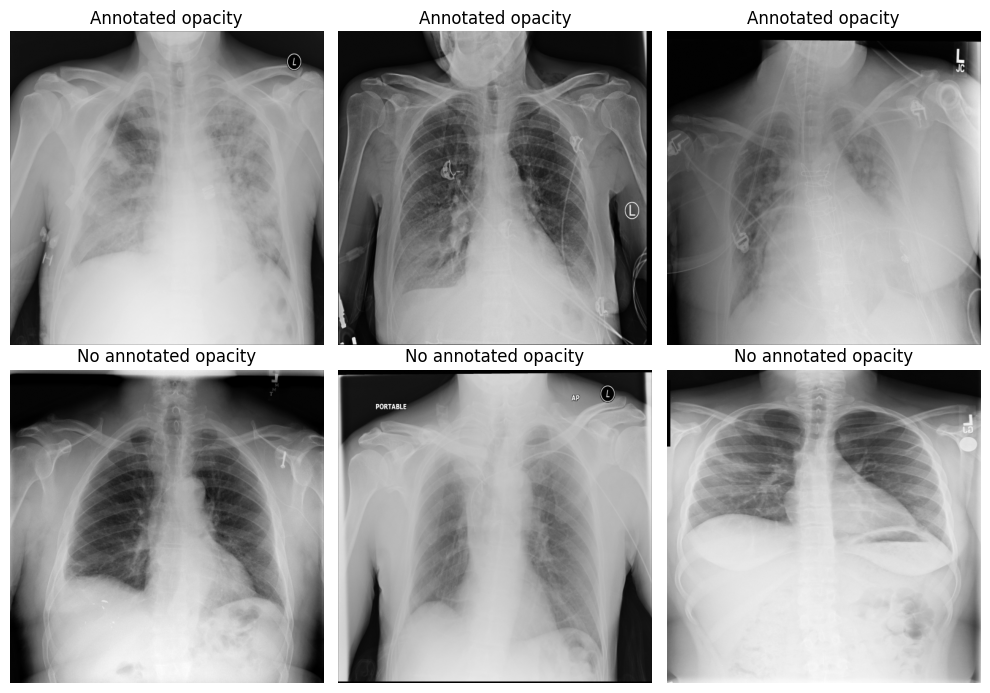

In [6]:
# Display positive and negative test examples without changing the query
positive = manifest.loc[manifest['Target'] == 1].sample(3, random_state=SEED)
negative = manifest.loc[manifest['Target'] == 0].sample(3, random_state=SEED)
samples = pd.concat([positive, negative]).reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, row in zip(axes.flat, samples.itertuples(index=False)):
    with Image.open(row.image) as image:
        ax.imshow(image, cmap='gray')
    ax.set_title('Annotated opacity' if row.Target else 'No annotated opacity')
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=180)
plt.show()
plt.close(fig)


In [7]:
adapter = manifest[['image']].copy()
adapter['label'] = manifest['Target'].map(lambda target: str([int(target)]))
adapter['class'] = manifest['Target'].map(lambda target: str([QUERY_FINDING.lower()] if target else []))
EVAL_CSV = RESULTS / 'rsna_test_adapter.csv'
adapter.to_csv(EVAL_CSV, index=False)
print('RSNA evaluation CSV:', len(adapter), 'images')


RSNA evaluation CSV: 5337 images


In [8]:
# Download the released checkpoint and backbones
api = HfApi()
MODEL_REPO = 'maxxyouu/AlphaRAD'
TEXT_REPO = 'sentence-transformers/all-mpnet-base-v2'
IMAGE_REPO = 'StanfordAIMI/dinov2-base-xray-224'
TEXT_REVISION = api.model_info(TEXT_REPO).sha
IMAGE_REVISION = api.model_info(IMAGE_REPO).sha
attached_checkpoints = list(INPUT.rglob('eccv_mpnet_518.tar'))
if len(attached_checkpoints) > 1:
    raise ValueError('Attach only one copy of eccv_mpnet_518.tar.')
if attached_checkpoints:
    CHECKPOINT = attached_checkpoints[0]
    MODEL_REVISION = None
else:
    MODEL_REVISION = api.model_info(MODEL_REPO).sha
    CHECKPOINT = Path(hf_hub_download(
        repo_id=MODEL_REPO, filename='xraydinov2_mpnet/eccv_mpnet_518.tar',
        revision=MODEL_REVISION,
    ))
TEXT_DIR = Path(snapshot_download(
    repo_id=TEXT_REPO, revision=TEXT_REVISION,
    allow_patterns=[
        'config.json', 'model.safetensors', 'vocab.txt', 'tokenizer.json',
        'tokenizer_config.json', 'special_tokens_map.json',
    ],
))
IMAGE_DIR = Path(snapshot_download(
    repo_id=IMAGE_REPO, revision=IMAGE_REVISION,
    allow_patterns=['config.json', 'model.safetensors', 'preprocessor_config.json'],
))
print('Checkpoint:', CHECKPOINT.name)


xraydinov2_mpnet/eccv_mpnet_518.tar:   0%|          | 0.00/791M [00:00<?, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

Checkpoint: eccv_mpnet_518.tar


In [9]:
# Set local backbone and tokenizer paths
source_path = REPO / 'cxrclip/evaluator.py'
source = subprocess.check_output(
    ['git', '-C', str(REPO), 'show', f'{REPO_COMMIT}:cxrclip/evaluator.py'], text=True,
)
old_text = "'cache_path/to/ sentence-transformers/all-mpnet-base-v2 or Laihaoran/BioClinicalMPBERT'"
old_image = "'cache_path/to/xraydinov2'"
if source.count(old_text) != 1 or source.count(old_image) != 1:
    raise ValueError('The expected official cache placeholders have changed.')
source = source.replace(old_text, repr(str(TEXT_DIR)))
source = source.replace(old_image, repr(str(IMAGE_DIR)))
image_line = f"ckpt['config']['model']['image_encoder']['cache_dir'] = {str(IMAGE_DIR)!r}"
source = source.replace(
    image_line,
    image_line + "\n        ckpt['config']['tokenizer']['cache_dir'] = " + repr(str(TEXT_DIR)),
)
compile(source, str(source_path), 'exec')
source_path.write_text(source)
print('Configured official evaluator cache paths.')


Configured official evaluator cache paths.


In [10]:
# Register the binary RSNA query and load the official model
from omegaconf import OmegaConf
from cxrclip import seed_everything
from cxrclip.evaluator import Evaluator
from cxrclip.evaluator_utils import disease_list_mapping, disease_name_mapping, get_class_list
from cxrclip.prompt import constants
from cxrclip.util.utils import curate_dqn_input_labels

seed_everything(SEED)
constants.RSNA_PNEUMONIA = [QUERY_FINDING]
loader_config = OmegaConf.to_container(
    OmegaConf.load(REPO / 'configs/dataloader/dataloader_256.yaml'), resolve=False,
)
loader_config['test'].update(
    batch_size=INFERENCE_BATCH_SIZE, num_workers=NUM_WORKERS, prefetch_factor=2,
    shuffle=False, drop_last=False,
)
eval_config = {
    'test': {'checkpoint': [str(CHECKPOINT)], 'seed': SEED},
    'data_test': {DATASET_KEY: {
        'name': DATASET_KEY, 'data_type': 'image_classification',
        'data_path': str(EVAL_CSV), 'n_class': 1, 'normalize': 'xraydino',
    }},
    'dataloader': loader_config,
}
evaluator = Evaluator(eval_config, [str(CHECKPOINT)], 'test')
if evaluator.zero_shot_method != 'zeroshot_binary_dqn' or not evaluator.model.enable_multihead_radzero_forward_pass:
    raise ValueError('The checkpoint must use AlphaRAD factorized zero-shot scoring.')
for parameter in evaluator.model.parameters():
    parameter.requires_grad_(False)
LABELS = get_class_list(DATASET_KEY)
prompts = [curate_dqn_input_labels(
    disease_name_mapping(label), evaluator.prompt_template,
    evaluator.observation_explanation, evaluator.anonymize_observation_explanation,
) for label in LABELS]
print('Fixed query:', prompts[0])
print('Checkpoint test transform:', evaluator.config['transform'].get('test'))


Device: cuda
Fixed query: There is pneumonia.
Checkpoint test transform: {'Resize': {'size': 518}, 'CenterCrop': {'size': 518}}


In [11]:
# Preserve the batch dimension 
official_encode_image = evaluator.encode_image

def encode_image_with_batch_axis(images):
    encoded = official_encode_image(images)
    batch_size = images.shape[0]
    for key in ['cls_token', 'cls2_token', 'cls_token_raw', 'cls2_token_raw']:
        if encoded[key] is not None:
            encoded[key] = [feature.reshape(batch_size, -1) for feature in encoded[key]]
    for key in ['patch_tokens', 'patch_tokens_raw']:
        if encoded[key] is not None:
            encoded[key] = [feature.reshape(batch_size, -1, feature.shape[-1]) for feature in encoded[key]]
    return encoded

evaluator.encode_image = encode_image_with_batch_axis


In [12]:
captured = {}
official_gather = evaluator.gather_zeroshot_dqn_classification_statistics

def capture_predictions(class_list, predictions, label_names):
    captured['class_list'] = list(class_list)
    captured['predictions'] = np.asarray(predictions)
    captured['label_names'] = label_names
    return official_gather(class_list, predictions, label_names)

evaluator.gather_zeroshot_dqn_classification_statistics = capture_predictions
evaluation_start = time.perf_counter()
official_results = evaluator.evaluate_clip_offline(str(CHECKPOINT), DATASET_KEY)
evaluation_seconds = time.perf_counter() - evaluation_start
score_block = official_results['zeroshot_binary']
score_array = captured['predictions']
if score_array.shape != (len(manifest), 1, 1) or not np.isfinite(score_array).all():
    raise ValueError(f'Unexpected binary score array: {score_array.shape}')
scores = score_array[:, 0, 0]
truth = np.asarray([
    int(disease_name_mapping(QUERY_FINDING) in disease_list_mapping(row))
    for row in captured['label_names']
], dtype=int)
if captured['class_list'] != LABELS or not np.array_equal(truth, manifest['Target'].to_numpy()):
    raise ValueError('The evaluator targets do not match the RSNA manifest.')
dataset = evaluator.data_loader_dict[DATASET_KEY].dataset
if dataset.df['image'].tolist() != manifest['image'].tolist():
    raise ValueError('The evaluator changed the test image order.')
predicted = (scores > THRESHOLD).astype(int)
metrics = dict(score_block[QUERY_FINDING])
metrics['threshold'] = THRESHOLD
print(pd.Series(metrics).round(3).to_string())
print(f'Evaluation time: {evaluation_seconds / 60:.1f} minutes')


missing: []
unexpected: ['logit_scale_aux']


[rsna_pneumonia]: 100%|██████████| 2669/2669 [10:36<00:00,  4.19it/s]


AUROC        0.832
PR_AUROC     0.549
Accuracy     0.778
F1           0.122
Precision    0.631
Recall       0.067
threshold    0.500
Evaluation time: 10.6 minutes


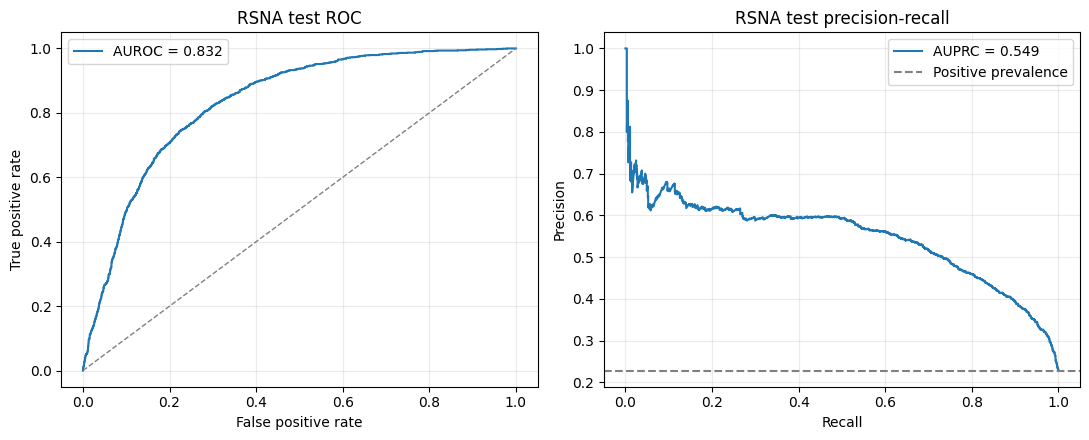

In [13]:
# Plot test ROC and precision-recall curves 
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(truth, scores)
precision, recall, _ = precision_recall_curve(truth, scores)
axes[0].plot(fpr, tpr, label=f'AUROC = {metrics["AUROC"]:.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(title='RSNA test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].plot(recall, precision, label=f'AUPRC = {metrics["PR_AUROC"]:.3f}')
axes[1].axhline(truth.mean(), color='gray', linestyle='--', label='Positive prevalence')
axes[1].set(title='RSNA test precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


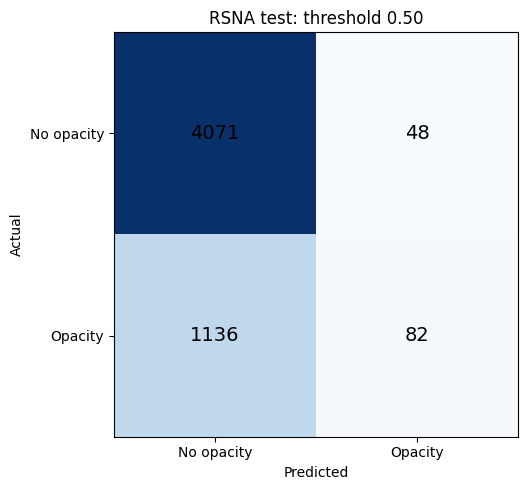

In [14]:
# Plot the test confusion matrix
matrix = confusion_matrix(truth, predicted, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(matrix, cmap='Blues')
for row in range(2):
    for column in range(2):
        ax.text(column, row, str(matrix[row, column]), ha='center', va='center', fontsize=14)
ax.set(
    title=f'RSNA test: threshold {THRESHOLD:.2f}',
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=['No opacity', 'Opacity'], yticklabels=['No opacity', 'Opacity'],
    xlabel='Predicted', ylabel='Actual',
)
fig.tight_layout()
fig.savefig(RESULTS / 'confusion_matrix.png', dpi=180)
plt.show()
plt.close(fig)


In [15]:
# Save predictions, metrics, source revisions, settings, and computation time
import importlib.metadata

predictions_df = manifest[['patientId', 'Target', 'dicom_path']].copy()
predictions_df['score'] = scores
predictions_df['prediction'] = predicted
predictions_df.to_csv(RESULTS / 'predictions.csv', index=False)
manifest.to_csv(RESULTS / 'test_manifest.csv', index=False)
pd.Series(metrics, name='value').to_csv(RESULTS / 'test_metrics.csv')

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

run_info = {
    'model': 'AlphaRAD', 'protocol': 'zero-shot RSNA binary classification',
    'paper_url': 'https://arxiv.org/abs/2609.01757',
    'source_repo': REPO_URL, 'source_commit': REPO_COMMIT,
    'checkpoint_sha256': sha256(CHECKPOINT), 'model_hub_revision': MODEL_REVISION,
    'text_hub_revision': TEXT_REVISION, 'image_hub_revision': IMAGE_REVISION,
    'split_source': SPLIT_REPO, 'split_revision': SPLIT_REVISION,
    'split_filename': SPLIT_FILENAME, 'split_sha256': sha256(split_path),
    'source_labels_sha256': sha256(DATA_ROOT / 'stage_2_train_labels.csv'),
    'images': len(manifest), 'unique_ids': int(manifest.patientId.nunique()),
    'positive_images': int(truth.sum()), 'negative_images': int((truth == 0).sum()),
    'target': 'annotated opacity suspicious for pneumonia',
    'queries': LABELS, 'prompts': prompts, 'threshold': THRESHOLD, 'seed': SEED,
    'prompt_note': 'Pneumonia follows the cited RadZero RSNA query; AlphaRAD does not release its RSNA registry.',
    'task_training_epochs': TASK_EPOCHS, 'task_trained_parameters': 0,
    'inference_batch_size': INFERENCE_BATCH_SIZE,
    'model_parameters': sum(parameter.numel() for parameter in evaluator.model.parameters()),
    'dicom_conversion': 'official resize_dicom_and_save; do_resize=True',
    'normalization': evaluator.config['image_model']['normalize'],
    'test_transform': evaluator.config['transform'].get('test'),
    'adapter_changes': 'RSNA query registry and CSV; local cache paths; restore singleton image batch axes without changing feature values.',
    'released_checkpoint_reference_AUROC': 0.841,
    'reference_note': 'Reference is informational; exact AlphaRAD RSNA prompt and converted pixels are not supplied.',
    'metrics': {key: float(value) for key, value in metrics.items()},
    'dicom_preparation_seconds': conversion_seconds,
    'evaluation_seconds': evaluation_seconds,
    'total_notebook_seconds': time.perf_counter() - RUN_START,
    'device': torch.cuda.get_device_name(0), 'torch_version': torch.__version__,
    'package_versions': {name: importlib.metadata.version(name) for name in [
        'numpy', 'pandas', 'scikit-learn', 'pydicom', 'SimpleITK',
        'transformers', 'huggingface-hub', 'albumentations',
    ]},
}
(RESULTS / 'run_info.json').write_text(json.dumps(run_info, indent=2))
(RESULTS / 'evaluation_config.json').write_text(json.dumps(eval_config, indent=2))
print('Saved results to:', RESULTS)
print(f'Total notebook time: {run_info["total_notebook_seconds"] / 60:.1f} minutes')


Saved results to: /kaggle/working/alpharad_rsna_results
Total notebook time: 15.3 minutes
